# VLM：LLaVA 图片问答 Full / LoRA 微调

[English](01_finetune.ipynb) | 简体中文

## Goal

原生 LLaVA 单图问答，assistant-only NLL；不包含视频、多轮对话或 Qwen-VL 后端。

本教程执行：校验数据 → 训练 → validation 选模 → test 报告 → 保存/重新加载 → 推理 → epoch 断点恢复 → 发布包预览。

**全部数据为合成样例，tiny 权重随机初始化。这里验证工程链路，不证明实际模型质量。** 首版只支持单进程、单设备 fp32，默认 CPU，无需下载模型。

## Setup

本地先运行 `python -m pip install -e '.[vlm,notebooks]'`。Colab 中下一格会克隆仓库并安装依赖；真实训练前把数据与输出放到 Google Drive 等持久化存储，避免运行时断开后丢失。

In [1]:
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    checkout = Path("/content/advai-notebooks")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-e",
                    f"{checkout}[vlm,notebooks]"], check=True)
    os.chdir(checkout)

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
print("Repository ready; install .[vlm,notebooks] locally if needed.")

Repository ready; install .[vlm,notebooks] locally if needed.


## Steps — 配置和数据检查

新输出目录避免覆盖旧实验。数据必须包含独立的 train / validation / test；source group、episode 与重复内容不能跨 split。归一化（VLA/VM）只使用 train。

In [2]:
import json
from uuid import uuid4

from advai_notebooks.common.runtime import setup
from advai_notebooks.vlm.config import load_config
from advai_notebooks.vlm.data import load_data, prepare_data
from advai_notebooks.vlm.model import VLMModel
from advai_notebooks.vlm.pipeline import run
from advai_notebooks.vlm.evaluate import evaluate
from advai_notebooks.vlm.publish import publish
from transformers.utils import logging
logging.disable_progress_bar()

cfg = load_config(ROOT / "configs/vlm/smoke.yaml")
cfg.output_dir = f"outputs/vlm/notebook-{uuid4().hex[:8]}"
# Change method to "lora" BEFORE run to train language q_proj/v_proj adapters.
model = VLMModel(cfg.model, setup(cfg), cfg.root, cfg.training)
rows, summary = load_data(cfg)
prepared = prepare_data(rows, model, cfg, fit=True)
print(json.dumps({"data": summary, "prepared_rows": {k: len(v) for k, v in prepared.items()}}, indent=2))

{
  "data": {
    "rows": 8,
    "splits": {
      "train": 4,
      "validation": 2,
      "test": 2
    },
    "fingerprint": "e09ba4492a8f828252819f1bbdb06a4b9e227945de0d54bf1d8affd2a7403ea6",
    "media_fingerprint": "6d2de0e2af4d88a73acf47d19511da739f777977b167bcfb23ad7c2d2c546e8e"
  },
  "prepared_rows": {
    "train": 4,
    "validation": 2,
    "test": 2
  }
}


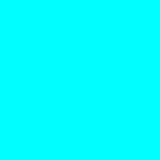

{'prompt': 'what color is the square ?', 'reference': 'cyan'}


In [3]:
from PIL import Image
from IPython.display import display

example = next(row for row in rows if row["split"] == "test")
display(Image.open(example["image"]).resize((160, 160), resample=Image.Resampling.NEAREST))
print({"prompt": example["prompt"], "reference": example["answer"]})

### 训练、验证与选模

选模使用 validation 的 NLL（越低越好），包括 epoch 0 基线；test 不参与选模。

`export/` 保存 validation 最优模型，`latest_export/` 保存最后一轮。保留 baseline、每轮 checkpoint、优化器/RNG、环境与数据/来源指纹。

In [4]:
report = run(cfg)
print(json.dumps({
    "baseline_test": report["baseline_test"]["metrics"],
    "selected_test": report["finetuned_test"]["metrics"],
    "selected_epoch": report["training"]["best_epoch"],
    "completed_epoch": report["training"]["epoch"],
}, indent=2))
assert report["training"]["epoch"] == cfg.training.epochs

{
  "baseline_test": {
    "nll": 3.588529348373413,
    "perplexity": 36.18082738839912
  },
  "selected_test": {
    "nll": 3.480757474899292,
    "perplexity": 32.48431881510448
  },
  "selected_epoch": 2,
  "completed_epoch": 2
}


## Checks — 原生导出、重新加载与推理

重新加载后重新计算 held-out 指标，并检查与训练报告一致。tiny 生成文本/动作/状态只用于接口演示，不应用于业务或机器人执行。

In [5]:
loaded = VLMModel.load(report["export"])
reloaded_metrics = evaluate(loaded, prepare_data(rows, loaded, cfg, fit=False), cfg, "test")
assert reloaded_metrics["metrics"] == report["finetuned_test"]["metrics"]
response = loaded.chat(example["image"], example["prompt"])
assert isinstance(response, str)
print({"tiny_response": response, "reference": example["answer"]})

{'tiny_response': 'green', 'reference': 'cyan'}


### 严格 epoch 断点恢复

下面从已完成实验恢复（幂等，不再训练）。中途退出时也是同一个入口，从最新已完成 epoch 继续。配置、数据、源码、相关依赖必须不变；精确中断恢复由回归测试覆盖。

In [6]:
resumed = run(cfg, resume=cfg.path(cfg.output_dir) / "latest")
assert resumed["training"] == report["training"]
print({"resume_epoch": resumed["training"]["epoch"], "history_unchanged": True})

{'resume_epoch': 2, 'history_unchanged': True}


### 离线发布预览

仅检查推理文件白名单和重新加载，不连接 Hub、不创建仓库、不上传数据。真正发布需要显式去掉 dry_run，并确认基座许可证、数据授权与模型卡。

In [7]:
plan = publish(report["export"], "example/vlm-training-guide", dry_run=True)
assert plan["status"] == "dry_run"
names = [item["path"] for item in plan["files"]]
assert not any("training_state" in name for name in names)
print({"status": plan["status"], "inference_files": names})

{'status': 'dry_run', 'inference_files': ['README.md', 'advai_metadata.json', 'chat_template.jinja', 'config.json', 'generation_config.json', 'model.safetensors', 'processor_config.json', 'tokenizer.json', 'tokenizer_config.json']}


## Next Steps

- [完整 Guide](../../docs/vlm.zh-CN.md)：数据字段、推理 JSON、方法与局限。
- [配置目录](../../configs/vlm/README.md)：full/LoRA smoke 和固定 LLaVA 7B revision 的真实基座模板（未做 7B GPU 训练验证，内存需求高）。
- 先用 smoke 检查数据契约；真实配置的模型感知校验会加载权重，同样需要足够硬件内存。更换数据或配置时使用新的输出目录。
- 对真实任务增加适当指标与人工检查：回答正确性/grounding，不能只看 NLL。

CPU smoke 和输出重新加载已执行；CUDA/MPS、大型真实基座训练及机器人/视频能力不在本 Notebook 验证范围内。